# Task

For each subscriber, compare their revenue with their region: share of regional revenue, rank inside the region, and deviation from the regional mean. Telecom use case: finding high-value subscribers and anomalies by segment.

# Data
Synthetic telecom dataset: 200 subscribers with region, tariff and monthly revenue (lognormal distribution, heavy right tail like real ARPU).

In [24]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [25]:
rng = np.random.default_rng(42)
n = 200

df = pd.DataFrame({
    "subscriber_id": range(1, n + 1),
    "region": rng.choice(["Astana", "Almaty", "Shymkent", "Karaganda"], size=n),
    "tariff": rng.choice(["Basic", "Plus", "Max"], size=n, p=[0.5, 0.3, 0.2]),
    "revenue": rng.lognormal(mean=8, sigma=0.5, size=n).round(0),
})
df.head(20)

,subscriber_id,region,tariff,revenue
0,1,Astana,Max,2576.0
1,2,Karaganda,Plus,2831.0
2,3,Shymkent,Basic,2628.0
3,4,Almaty,Max,3217.0
4,5,Almaty,Plus,6221.0
5,6,Karaganda,Plus,826.0
6,7,Astana,Basic,2648.0
7,8,Shymkent,Basic,3256.0
8,9,Astana,Basic,3456.0
9,10,Astana,Max,2475.0


In [26]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 4 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   subscriber_id  200 non-null    int64  
 1   region         200 non-null    str    
 2   tariff         200 non-null    str    
 3   revenue        200 non-null    float64
dtypes: float64(1), int64(1), str(2)
memory usage: 6.4 KB


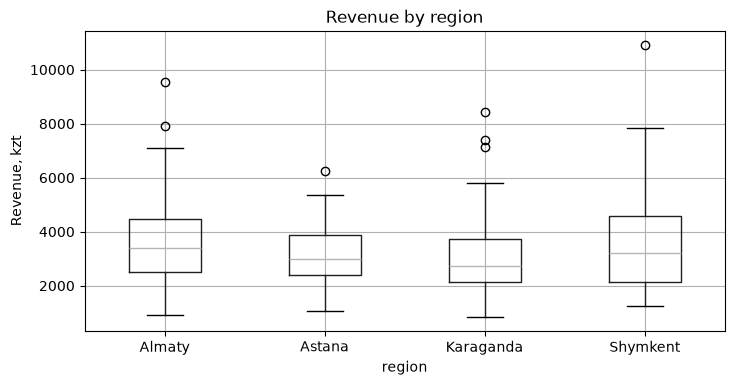

In [27]:
df.boxplot(column='revenue', by='region', figsize=(8,4))
plt.title('Revenue by region')
plt.suptitle('')
plt.ylabel('Revenue, kzt')
plt.show()

## 3. Transform
Add group-level metrics back to every row with `groupby().transform()`.

In [28]:
df['region_mean'] = df.groupby('region')['revenue'].transform('mean')
df['diff_from_mean'] = df['revenue'] - df['region_mean']

print(df.shape)
df.head(20)

(200, 6)


,subscriber_id,region,tariff,revenue,region_mean,diff_from_mean
0,1,Astana,Max,2576.0,3096.326087,-520.326087
1,2,Karaganda,Plus,2831.0,3186.470588,-355.470588
2,3,Shymkent,Basic,2628.0,3699.120000,-1071.120000
3,4,Almaty,Max,3217.0,3643.849057,-426.849057
4,5,Almaty,Plus,6221.0,3643.849057,2577.150943
5,6,Karaganda,Plus,826.0,3186.470588,-2360.470588
6,7,Astana,Basic,2648.0,3096.326087,-448.326087
7,8,Shymkent,Basic,3256.0,3699.120000,-443.120000
8,9,Astana,Basic,3456.0,3096.326087,359.673913
9,10,Astana,Max,2475.0,3096.326087,-621.326087


In [29]:
df['share_in_region'] = df['revenue'] / df.groupby('region')['revenue'].transform('sum')
df['rank_in_region'] = df.groupby('region')['revenue'].rank(ascending=False)

df.sort_values(['region', 'rank_in_region']).head(10)

,subscriber_id,region,tariff,revenue,region_mean,diff_from_mean,share_in_region,rank_in_region
87,88,Almaty,Basic,9546.0,3643.849057,5902.150943,0.049429,1.0
164,165,Almaty,Max,7907.0,3643.849057,4263.150943,0.040943,2.0
21,22,Almaty,Plus,7088.0,3643.849057,3444.150943,0.036702,3.0
139,140,Almaty,Basic,7047.0,3643.849057,3403.150943,0.036490,4.0
90,91,Almaty,Max,6648.0,3643.849057,3004.150943,0.034423,5.0
4,5,Almaty,Plus,6221.0,3643.849057,2577.150943,0.032212,6.0
193,194,Almaty,Basic,6103.0,3643.849057,2459.150943,0.031601,7.0
93,94,Almaty,Max,5737.0,3643.849057,2093.150943,0.029706,8.0
19,20,Almaty,Plus,5710.0,3643.849057,2066.150943,0.029566,9.0
168,169,Almaty,Basic,5106.0,3643.849057,1462.150943,0.026439,10.0


# Apply
Custom logic per group with `groupby().apply()`.

In [30]:
top3 = (
    df.groupby('region')
    .apply(lambda g: g.nlargest(3, 'revenue'))
    .reset_index(level=0)
)
top3[['region', 'subscriber_id', 'tariff', 'revenue', 'share_in_region']]

,region,subscriber_id,tariff,revenue,share_in_region
87,Almaty,88,Basic,9546.0,0.049429
164,Almaty,165,Max,7907.0,0.040943
21,Almaty,22,Plus,7088.0,0.036702
77,Astana,78,Max,6252.0,0.043895
22,Astana,23,Basic,5371.0,0.037709
188,Astana,189,Plus,5074.0,0.035624
165,Karaganda,166,Basic,8421.0,0.051818
36,Karaganda,37,Max,7408.0,0.045585
24,Karaganda,25,Basic,7129.0,0.043868
191,Shymkent,192,Basic,10925.0,0.059068


In [31]:
df.sort_values('revenue', ascending=False).groupby('region').head(3)

,subscriber_id,region,tariff,revenue,region_mean,diff_from_mean,share_in_region,rank_in_region
191,192,Shymkent,Basic,10925.0,3699.120000,7225.880000,0.059068,1.0
87,88,Almaty,Basic,9546.0,3643.849057,5902.150943,0.049429,1.0
165,166,Karaganda,Basic,8421.0,3186.470588,5234.529412,0.051818,1.0
164,165,Almaty,Max,7907.0,3643.849057,4263.150943,0.040943,2.0
179,180,Shymkent,Max,7853.0,3699.120000,4153.880000,0.042459,2.0
36,37,Karaganda,Max,7408.0,3186.470588,4221.529412,0.045585,2.0
24,25,Karaganda,Basic,7129.0,3186.470588,3942.529412,0.043868,3.0
21,22,Almaty,Plus,7088.0,3643.849057,3444.150943,0.036702,3.0
12,13,Shymkent,Basic,7070.0,3699.120000,3370.880000,0.038225,3.0
77,78,Astana,Max,6252.0,3096.326087,3155.673913,0.043895,1.0


In [32]:
top3_fast = df.sort_values("revenue", ascending=False).groupby("region").head(3)

print(set(top3.index) == set(top3_fast.index))
print(top3_fast.sort_values(["region", "revenue"], ascending=[True, False]).index.tolist())

True
[87, 164, 21, 77, 22, 188, 165, 36, 24, 191, 179, 12]


# Experiment
Mean vs median as the regional baseline (heavy-tailed revenue).

In [33]:
df['region_median'] = df.groupby('region')['revenue'].transform('median')
df['diff_from_median'] = df['revenue'] - df['region_median']

df.groupby('region')[['region_mean', 'region_median']].first()

,region_mean,region_median
region,,
Almaty,3643.849057,3412.0
Astana,3096.326087,2970.5
Karaganda,3186.470588,2712.0
Shymkent,3699.120000,3225.0


# What I learned
- `groupby().transform()` returns a group value to every row (same number of rows), unlike `agg`, which collapses each group into one row.
- `groupby().apply()` runs a custom function on the whole group; it is flexible but slow, so built-in methods (e.g. `sort_values` + `head`) are preferred.
- Revenue is right-skewed: the mean is above the median in every region, so the median can be a more honest baseline for ARPU comparisons.